In [1]:
path_to_dodem = '/Users/jmdunca2/do-dem/'
from sys import path as sys_path
sys_path.append(path_to_dodem+'/dodem/')

import HARP_and_age as haa
import all_nu_analysis as ana

import pickle
import importlib

import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u

from astropy.visualization import quantity_support
quantity_support()

with open('/Users/jmdunca2/do-dem/reference_files/all_targets_postghost_postshut.pickle', 'rb') as f:
    all_targets = pickle.load(f)
    

In [2]:
all_targets.keys()

dict_keys(['01-nov-14_1', '01-nov-14_2', '11-dec-14', '19-feb-16', '22-apr-16_1', '22-apr-16_2', '26-jul-16_1', '27-jul-16_1', '26-jul-16_2', '10-oct-17', '29-may-18_1', '29-may-18_2', '07-sep-18', '09-sep-18', '10-sep-18', '12-apr-19', '13-apr-19', '29-jan-20', '06-jun-20', '07-jun-20', '08-jun-20', '09-jun-20', '08-jan-21', '14-jan-21', '20-jan-21', '29-apr-21', '03-may-21_1', '03-may-21_2', '30-jul-21_1', '30-jul-21_2', '17-nov-21_1', '19-nov-21', '20-nov-21', '22-nov-21_1', '22-nov-21_2', '03-jun-22_1', '03-jun-22_2', '06-sep-22', '09-dec-22', '17-nov-21_2', '21-nov-21', '30-jan-20', '20-jul-21', '24-feb-22', '25-feb-22', '27-feb-22', '18-mar-23_2', '11-dec-22_2'])

The regions with HARPs associated have 'HARP params' dictionaries within the larger target dictionary. These include identified times corresponding to the orbits during which NuSTAR observed that region ('per_orbit_intersect_indices' - which index the 'harptimes' array). 

In [3]:
poii=all_targets['07-sep-18']['HARP params'][0]['per_orbit_intersect_indices']
print("Indices for each of the three orbits:")
print(poii)
print("HARP times within NuSTAR orbit 1:")
all_targets['07-sep-18']['HARP params'][0]['harptimes'][poii[0]]



Indices for each of the three orbits:
[array([557, 558, 559, 560, 561]), array([565, 566, 567, 568, 569]), array([572, 573, 574, 575, 576])]
HARP times within NuSTAR orbit 1:


array([datetime.datetime(2018, 9, 7, 15, 0),
       datetime.datetime(2018, 9, 7, 15, 12),
       datetime.datetime(2018, 9, 7, 15, 24),
       datetime.datetime(2018, 9, 7, 15, 36),
       datetime.datetime(2018, 9, 7, 15, 48)], dtype=object)

More specifically, we would like to get HARP parameters specifically for each of our contiguous quiescent times. For quiescent times which are short enough to not contain any HARP times (which only occur at 12 minute intervals), we want to get the closest adjacent HARP time. The following gets the indices of these for all contiguous intervals for each region.

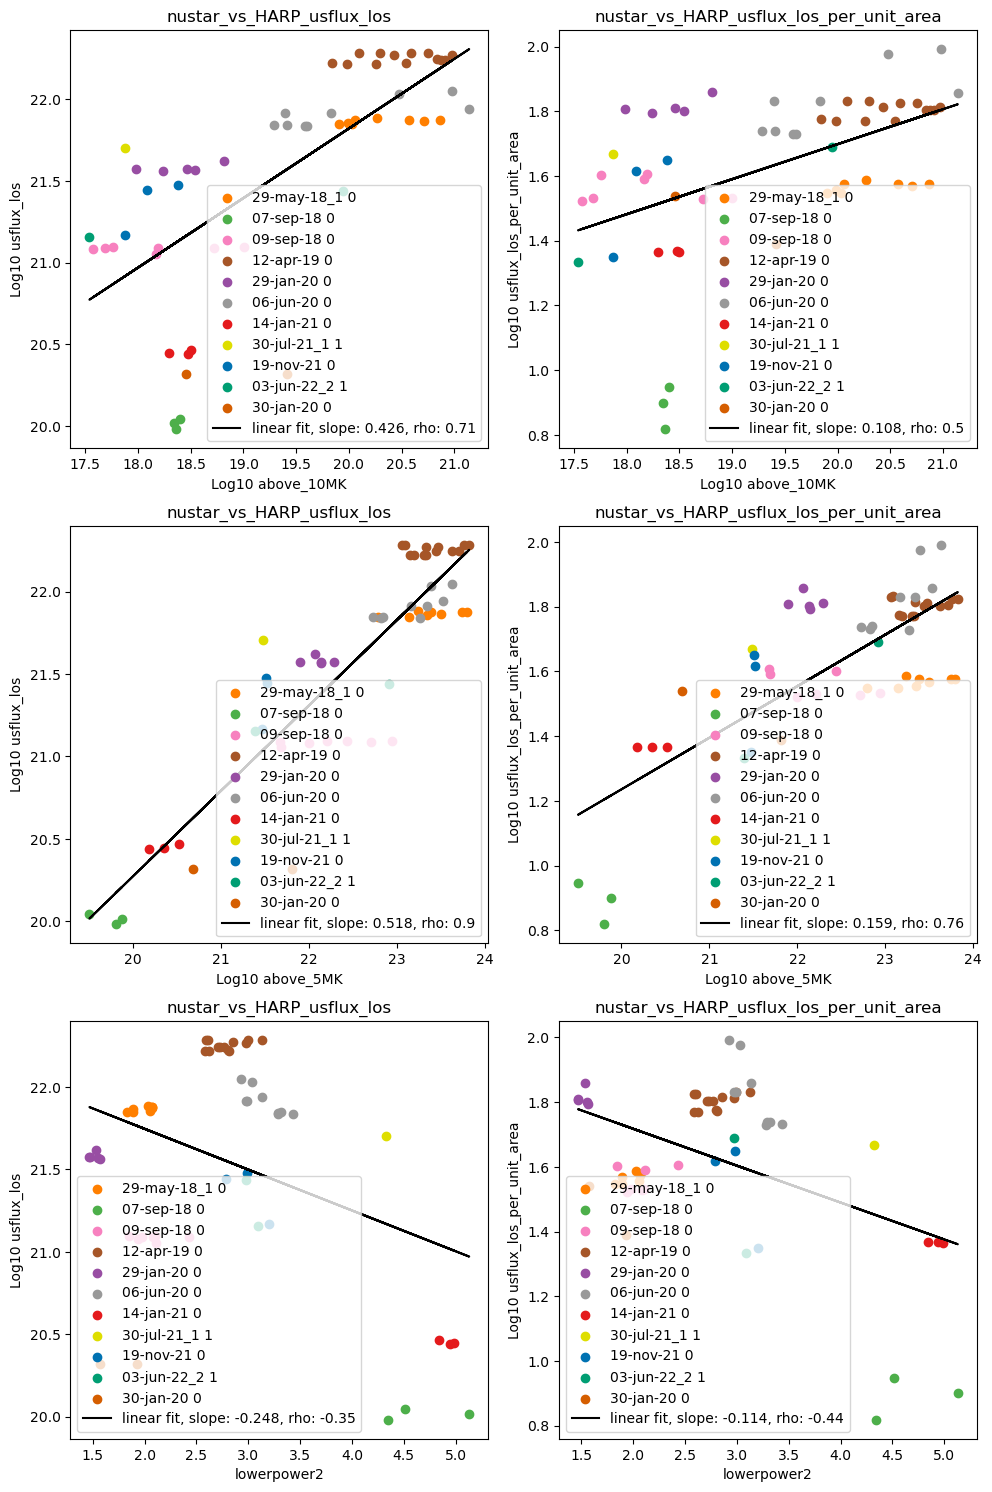

In [8]:


def plot_params_quiescent_intervals(param, nuparam, plotlog=True, plotlognu=True,
                                    perarea=True,
                                   input_ax=[]):

    cb_many_colors = [
        '#377eb8', '#ff7f00', '#4daf4a', # Blue, Orange, Green
        '#f781bf', '#a65628', '#984ea3', # Pink, Brown, Purple
        '#999999', '#e41a1c', '#dede00', # Gray, Red, Yellow
        ('#0072b2'), ('#009e73'), ('#d55e00'), # Okabe-Ito Blue, Green, Vermillion
        'black'
    ]
    symbols = ['o', '^']
    
    colorind=0
    symbolind=0

    if input_ax:
        ax=input_ax
    else:
        fig = plt.figure(figsize=(7, 7), tight_layout = {'pad': 1})
        ax = fig.add_subplot(1,1,1)

    
    allnus=[]
    allharps=[]
    
    
    #for all keys 
    for kk in all_targets.keys():
        #print(kk)
    
        #For each region (finding total number via length of 'loc' list, as one location type is specified for each analyzed region)
        for r in range(0, len(all_targets[kk]['loc'])):
            #print(r)
            
            #Quiet times for that region
            qts = all_targets[kk]['per_region_quiet_time_intervals'][r]
            #Quiet time contiguous interval time lists
            qti = all_targets[kk]['per_region_quiet_contiguous_times'][r]
            #Quiet time contiguous interval file lists
            qtif = all_targets[kk]['per_region_quiet_contiguous_files'][r]
            
            #Quick ugly fix for an issue where np.any(qts) didn't always acurately determine whether there were 
            #any quiet times due to nested lists
            well=[]
            for nn in qts:
                well.append(bool(nn))
    
            #If there are any quiet times for this region
            if np.any(well):
    
                
                #if there are HARP params for this region
                if all_targets[kk]['HARP params'][r]:
    
                    # fig, ax = plt.subplots(figsize=(5, 3))
                    # ax.set_xlim([17, 21])
                    # ax.set_ylim([19,23])
                    # ax.set_title(kk+' '+str(r))
    
                    doubles = ['10-sep-18 0', '13-apr-19 0', '07-jun-20 0', '08-jun-20 0',
                                      '20-nov-21 0', '21-nov-21 0', '22-nov-21_1 0']
                    krstr = kk+' '+str(r)
                    checklist = [(krstr == d) for d in doubles]
                    if not np.any(checklist):
                        if colorind < 12:
                            colorind+=1
                        if colorind == 12:
                            colorind = 0
                            symbolind=1
    
                    first=True
                    included=False
                    
                    #Array of HARP times for the region
                    hts=all_targets[kk]['HARP params'][r]['harptimes']
    
                    #print(all_targets[kk]['HARP params'][r].keys())
                    #print('')
        
                    all_harp_intervals=[]
                    all_intervals=[]
                    all_interval_files=[]
                    
                    #For each orbit
                    for o in range(0, len(qts)):
    
                        intervals = qti[o]
                        # #Find contiguous quiescent times (potentially made up of more than one analysis interval)
                        # contiguous, intervals, int_inds = ana.check_contig(qts[o])
                        # #print('i:', intervals)
                        # #print('i0:', intervals[0])
                        # #print('')
                        
                        #If there are any quiescent intervals in this orbit
                        if intervals:
                            
                            #For each interval 
                            for jj in range(0, len(intervals)):
                                
                                #Beginning and end of the interval
                                i0, i1 = intervals[jj][0][0], intervals[jj][-1][1]
        
                                #HARP indices in interval
                                included_inds = np.where(np.logical_and(hts > i0, hts < i1))[0]
                                #print('ii: ', len(included_inds))
                                
                                #If there are no included indices
                                if len(included_inds) == 0:
                                    #print('NO HARPTIMES IN CONTIGUOUS INTERVAL: ', kk, 'region ', r, '|', i0, i1)
    
                                    #Find closest HARP time to interval and add index to list 
                                    diffz = [np.abs((hh-i0.datetime).total_seconds()) for hh in hts]
                                    closest_harp = np.where(diffz == np.min(diffz))[0]
                                    
                                    #Don't add an interval if it's more than a HARP timestep from the nearest HARP time
                                    if (np.min(diffz)*u.s).to(u.min) < 12*u.min:
                                        all_harp_intervals.append(closest_harp)
                                        all_intervals.append(intervals[jj])
                                        all_interval_files.append(qtif[o][jj])
                                else:
                                    all_harp_intervals.append(included_inds)
                                    all_intervals.append(intervals[jj])
                                    all_interval_files.append(qtif[o][jj])
                        
                    if all_harp_intervals:
                        #print('Region With HARP: ', kk, r)
                        
                        for jk in range(0, len(all_harp_intervals)):
                            #print('HARPTIME: ', hts[all_harp_intervals[jk]])
                            lon = all_targets[kk]['HARP params'][r]['lon_fwt'][all_harp_intervals[jk]]
         
                            if np.abs(np.mean(lon)) < 45:
                                included=True
    
                                harpvalue = np.mean(all_targets[kk]['HARP params'][r][param][all_harp_intervals[jk]])
                                aream = np.mean(all_targets[kk]['HARP params'][r]['harp_area'][all_harp_intervals[jk]])
        
                                nuparams=[]
                                for f_ in all_interval_files[jk]:
                                    with open(f_, 'rb') as f:
                                        data = pickle.load(f)
                                    if nuparam=='lowerpower2':
                                        npr = list(data['powerlaws2'][0])
                                    else:
                                        npr = data[nuparam]
                                    nuparams.append(npr)

                                #print(nuparam, nuparams)

                                if plotlognu:
                                    #print('mean ', np.mean(nuparams, axis=0))
                                    nuvalue = np.log10(np.mean(nuparams, axis=0)[0])
                                else:
                                    #print('mean ', np.mean(nuparams, axis=0))
                                    nuvalue = np.mean(nuparams, axis=0)[0]
    
                                if plotlog:
                                    if perarea:
                                        harpvalue /= aream
                                    harpvalue = np.log10(harpvalue)
                                else:
                                    if perarea:
                                        harpvalue /= aream
                                    
                                allnus.append(nuvalue)
                                allharps.append(harpvalue)
                               
        
                                #print(colorind)
                                if not np.any(checklist) and first:
                                    ax.scatter(nuvalue, harpvalue, 
                                            color=cb_many_colors[colorind],
                                           marker=symbols[symbolind],
                                           label=krstr)
                                    first=False
                                else:
                                    ax.scatter(nuvalue, harpvalue, 
                                            color=cb_many_colors[colorind],
                                           marker=symbols[symbolind])
                    if not included:
                        colorind-=1

    rho=round(np.corrcoef(allnus, allharps)[0,1],2)
    
    m, b = np.polyfit(allnus, allharps, 1)
    fity = np.array(allnus)*m + b
    ax.plot(allnus, fity, label='linear fit, slope: '+str(round(m,3))+', rho: '+str(round(rho,3)), color='black')
    ax.legend()
    
    ystring = param
    xstring = nuparam
    namestring='nustar_vs_HARP_'+param
    
    if plotlog:
        ystring = 'Log10 '+param
        
    if plotlognu:
        xstring = 'Log10 '+nuparam
    
    if perarea:
        namestring+='_per_unit_area'
        ystring+='_per_unit_area'
    
    ax.set_xlabel(xstring)
    ax.set_ylabel(ystring)
    ax.set_title(namestring)
    
    plt.savefig(namestring+'.png', dpi=300)



fig = plt.figure(figsize=(10, 15), tight_layout = {'pad': 1})

param='usflux_los'
nuparam='above_10MK'
ax = fig.add_subplot(3,2,1)
plot_params_quiescent_intervals(param, nuparam, plotlog=True, perarea=False, input_ax=ax)

param='usflux_los'
nuparam='above_10MK'
ax = fig.add_subplot(3,2,2)
plot_params_quiescent_intervals(param, nuparam, plotlog=True, perarea=True, input_ax=ax)

param='usflux_los'
nuparam='above_5MK'
ax = fig.add_subplot(3,2,3)
plot_params_quiescent_intervals(param, nuparam, plotlog=True, perarea=False, input_ax=ax)

param='usflux_los'
nuparam='above_5MK'
ax = fig.add_subplot(3,2,4)
plot_params_quiescent_intervals(param, nuparam, plotlog=True, perarea=True, input_ax=ax)

param='usflux_los'
nuparam='lowerpower2'
ax = fig.add_subplot(3,2,5)
plot_params_quiescent_intervals(param, nuparam, plotlog=True, plotlognu=False, perarea=False, input_ax=ax)

param='usflux_los'
nuparam='lowerpower2'
ax = fig.add_subplot(3,2,6)
plot_params_quiescent_intervals(param, nuparam, plotlog=True, plotlognu=False, perarea=True, input_ax=ax)



# param='totjh'
# nuparam='above_10MK'
# ax = fig.add_subplot(2,2,3)
# plot_params_quiescent_intervals(param, nuparam, plotlog=True, perarea=True, input_ax=ax)

# param='totjz'
# nuparam='above_10MK'
# ax = fig.add_subplot(2,2,4)
# plot_params_quiescent_intervals(param, nuparam, plotlog=True, perarea=True, input_ax=ax)

#handles, labels = ax.get_legend_handles_labels()
#fig.legend(handles, labels, loc='upper right')

In [ ]:
nn = False

nn == True

New item for targets dictionary: save a per-region files list (same content as the file list in res_files, but formatted per region and orbit.


In [6]:
import copy

for key in all_targets.keys():
    print(key)

    prqtf = []
    
    for r in range(0, len(all_targets[key]['loc'])):
    
        res_times = all_targets[key]['res_file_dict(s)'][r]['quiet times ']
        res_files = all_targets[key]['res_file_dict(s)'][r]['quiet files all-inst']
        pr_times =  all_targets[key]['per_region_quiet_time_intervals'][r]
    
        pr_files = copy.deepcopy(pr_times)
    
        for i in range(0, len(res_times)):
            rt=res_times[i]
            #fix weird issue where some cases instead of a Time object with a list of two times, it was a list of two time objects
            if isinstance(rt, list):
                from astropy.time import Time
                rt = Time(rt)
                all_targets[key]['res_file_dict(s)'][r]['quiet times '][i] = rt
                
            for o in range(0, len(pr_times)):
                #print(o, pr_times[o])
                for prt in range(0, len(pr_times[o])):
                    
                    if any(rt == pr_times[o][prt]):
                        # print('yus')
                        # print(rt)
                        # print(prt)
                        # print('')
                        pr_files[o][prt] = res_files[i]
    
        prqtf.append(pr_files)
        #print('==============================')
        
    print(prqtf)
    print(all_targets[key]['per_region_quiet_time_intervals'])
    all_targets[key]['per_region_quiet_time_files'] = prqtf
    print(all_targets[key]['per_region_quiet_time_files'])
    print('==============================')
    print('==============================')

01-nov-14_1
[[['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_1nov14_1/region_0//21-34-45_21-41-55/21-34-45_21-41-55_5.6_7.2_01-nov-14_1_MC_DEM_result_withparams.pickle', '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_1nov14_1/region_0//21-41-55_21-47-50/21-41-55_21-47-50_5.6_7.2_01-nov-14_1_MC_DEM_result_withparams.pickle']], [['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_1nov14_1/region_1//21-34-45_21-47-50/21-34-45_21-47-50_5.6_7.2_01-nov-14_1_MC_DEM_result_withparams.pickle']]]
[[[<Time object: scale='utc' format='datetime' value=[datetime.datetime(2014, 11, 1, 21, 34, 45)
 datetime.datetime(2014, 11, 1, 21, 41, 55)]>, <Time object: scale='utc' format='datetime' value=[datetime.datetime(2014, 11, 1, 21, 41, 55)
 datetime.datetime(2014, 11, 1, 21, 47, 50)]>]], [[<Time object: scale='utc' format='datetime' value=[datetime.datetime(2014, 11, 1, 21, 34, 45)
 datetime.datetime(2014, 11, 1, 21, 47, 50)]>]]]
[[['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_1nov14_1/region_0//21

New item for target dictionary: save the continuous quiescent interval groups for each region.

In [7]:

#for all keys 
for kk in all_targets.keys():
    print(kk)

    per_region_quiet_contiguous_times = []
    per_region_quiet_contiguous_files = []

    #For each region (finding total number via length of 'loc' list, as one location type is specified for each analyzed region)
    for r in range(0, len(all_targets[kk]['loc'])):
        print(r)

        region_quiet_contiguous = []
        region_quiet_contiguous_files = []
        
        #Quiet times for that region
        qts = all_targets[kk]['per_region_quiet_time_intervals'][r]
        #print('QTS: ', qts)
        
        #Quick ugly fix for an issue where np.any(qts) didn't always acurately determine whether there were 
        #any quiet times due to nested lists
        well=[]
        for nn in qts:
            if nn:
                well.append(True)
            else:
                well.append(False)
                
        #If there are any quiet times for this region
        if np.any(well):
                
            #For each orbit
            for o in range(0, len(qts)):
                
                #Find contiguous quiescent times (potentially made up of more than one analysis interval)
                contiguous, intervals, int_inds = ana.check_contig(qts[o])
                #print('i:', intervals)
                #print('i0:', intervals[0])
                #print('')
                
                region_quiet_contiguous.append(intervals)
                #print('INT INDS: ', int_inds)
                int_files=[]
                for int in int_inds:
                    start, stop = int
                    #print(all_targets[kk]['per_region_quiet_time_files'][r])
                    files = all_targets[kk]['per_region_quiet_time_files'][r][o][start:stop]
                    int_files.append(files)
                region_quiet_contiguous_files.append(int_files)

        per_region_quiet_contiguous_times.append(region_quiet_contiguous)
        per_region_quiet_contiguous_files.append(region_quiet_contiguous_files)


    all_targets[kk]['per_region_quiet_contiguous_times'] = per_region_quiet_contiguous_times
    all_targets[kk]['per_region_quiet_contiguous_files'] = per_region_quiet_contiguous_files


01-nov-14_1
0
1
01-nov-14_2
0
11-dec-14
0
19-feb-16
0
22-apr-16_1
0
22-apr-16_2
0
26-jul-16_1
0
1
27-jul-16_1
0
1
26-jul-16_2
0
10-oct-17
0
1
29-may-18_1
0
29-may-18_2
0
1
07-sep-18
0
09-sep-18
0
10-sep-18
0
12-apr-19
0
13-apr-19
0
29-jan-20
0
06-jun-20
0
07-jun-20
0
08-jun-20
0
09-jun-20
0
08-jan-21
0
14-jan-21
0
20-jan-21
0
29-apr-21
0
03-may-21_1
0
03-may-21_2
0
30-jul-21_1
0
1
30-jul-21_2
0
17-nov-21_1
0
19-nov-21
0
20-nov-21
0
22-nov-21_1
0
22-nov-21_2
0
03-jun-22_1
0
03-jun-22_2
0
1
06-sep-22
0
09-dec-22
0
1
17-nov-21_2
0
21-nov-21
0
30-jan-20
0
20-jul-21
0
1
24-feb-22
0
25-feb-22
0
27-feb-22
0
18-mar-23_2
0
11-dec-22_2
0


In [ ]:
all_targets['07-sep-18'].keys()